# ***Ujian Akhir Semester Menggunakan Data TimeSeries UCR***

## **Business Understanding**

### **1. Latar Belakang Bisnis**

Identifikasi karakteristik fisiologis manusia, khususnya berdasarkan pola biometrik seperti bentuk garis jari, merupakan salah satu bidang yang banyak dikembangkan dalam aplikasi kesehatan, penelitian forensik, dan sistem identifikasi otomatis. Pola kurva distal phalanx (ujung ruas jari) memiliki informasi yang dapat mencerminkan struktur biologis tertentu, termasuk kelompok usia. Dengan meningkatnya kebutuhan untuk analisis yang cepat, objektif, dan berbasis data, penggunaan metode klasifikasi otomatis terhadap sinyal time series menjadi semakin relevan. Dataset *DistalPhalanxOutlineAgeGroup* digunakan dalam penelitian ini untuk mengevaluasi kemampuan model dalam mengelompokkan usia berdasarkan pola kurva jari.

### **2. Permasalahan Bisnis**

Proses klasifikasi usia berdasarkan pola fisiologis umumnya masih dilakukan secara manual atau bergantung pada interpretasi manusia, sehingga memerlukan waktu yang lama dan rentan terhadap subjektivitas. Hal ini dapat menyebabkan ketidakkonsistenan hasil, terutama ketika volume data besar atau penyelisikan harus dilakukan secara cepat, seperti dalam studi biometrik atau proses identifikasi. Masalah bisnis utama yang ingin diselesaikan adalah bagaimana mengotomatisasi proses pengelompokan usia dengan memanfaatkan pola sinyal time series sehingga hasilnya lebih cepat, konsisten, dan dapat diandalkan.


### **3. Tujuan Bisnis**

Tujuan bisnis dari penelitian ini adalah menyediakan sebuah model klasifikasi yang mampu memprediksi kelompok usia individu secara otomatis berdasarkan pola outline distal phalanx. Model yang dikembangkan diharapkan dapat membantu mempercepat proses analisis, mengurangi ketergantungan pada interpretasi manual, serta meningkatkan efisiensi dalam proses identifikasi biometrik. Dengan adanya sistem otomatis, stakeholder seperti lembaga kesehatan, peneliti biometrik, maupun analis forensik dapat memperoleh hasil klasifikasi yang lebih cepat dan stabil.

### **4. Kriteria Kesuksesan Bisnis**

Suatu solusi dianggap berhasil secara bisnis apabila mampu mempercepat proses identifikasi usia dibandingkan metode manual, memberikan hasil yang konsisten, dan memiliki tingkat kesalahan yang dapat diterima dalam konteks penggunaan. Selain itu, keberhasilan juga diukur dari kemampuan model untuk digunakan sebagai alat bantu analisis yang praktis dan mudah diintegrasikan ke dalam sistem identifikasi atau aplikasi riset.


### **5. Pernyataan Masalah Data Science**

Permasalahan bisnis tersebut diterjemahkan menjadi masalah data science berupa pembangunan model *time series classification* untuk memprediksi tiga kelompok usia berdasarkan sinyal kurva distal phalanx. Secara khusus, tugas data mining yang dilakukan adalah membangun model klasifikasi dengan memanfaatkan pendekatan *1-Nearest Neighbor* menggunakan jarak Euclidean dan metode *Dynamic Time Warping* (DTW) untuk membandingkan performa keduanya. Model akan menerima deretan nilai numerik berdimensi 80 titik dan menghasilkan label usia yang sesuai.


### **6. Tujuan Data Science**

Tujuan data science dari proyek ini adalah menghasilkan model baseline yang akurat dan robust untuk dataset *DistalPhalanxOutlineAgeGroup*. Penelitian ini juga bertujuan membandingkan efektivitas dua pendekatan jarak—Euclidean dan DTW—dalam melakukan klasifikasi time series. Selain itu, analisis dilakukan untuk memastikan bahwa model yang dibangun mampu mengenali pola antar kelas dengan konsisten dan memberikan prediksi yang dapat diandalkan pada data uji.

### **7. Kriteria Evaluasi Teknis**

Keberhasilan teknis dievaluasi berdasarkan metrik performa seperti akurasi, confusion matrix, dan laporan klasifikasi. Model dinilai berhasil apabila mencapai akurasi yang kompetitif dibandingkan benchmark umum pada dataset UCR, serta menunjukkan distribusi prediksi yang stabil untuk setiap kelas. Selain itu, model diharapkan tidak menunjukkan indikasi overfitting yang signifikan dan mampu bekerja secara efektif pada data uji.


### **8. Asumsi dan Batasan**

Beberapa asumsi digunakan dalam penelitian ini, antara lain bahwa data telah dinormalisasi, tidak mengandung nilai hilang, serta memiliki panjang time series yang seragam. Dataset juga bersifat *univariate* sehingga tidak memerlukan proses ekstraksi fitur tambahan. Namun demikian, penelitian ini memiliki batasan berupa ukuran dataset yang relatif kecil, ketidakseimbangan antar kelas, serta pemodelan yang terbatas pada algoritma baseline tanpa arsitektur deep learning. Selain itu, penelitian dilakukan dalam batasan sumber daya komputasi Google Colab standar.

### **9. Risiko dan Mitigasi**

Risiko utama dalam analisis ini meliputi ketidakseimbangan distribusi kelas, pergeseran pola sinyal antar individu, serta kemungkinan bahwa model Euclidean tidak cukup sensitif terhadap variasi temporal. Untuk memitigasi risiko tersebut, digunakan metode DTW yang lebih adaptif terhadap pergeseran waktu, serta dilakukan evaluasi komparatif guna memilih metode terbaik. Penggunaan baseline model juga mengurangi risiko overfitting serta memberikan pondasi yang kuat untuk pengembangan model lanjutan.

## **Data Understanding**

### **Deskripsi Akuisisi Data**

Dataset yang digunakan dalam penelitian ini, *DistalPhalanxOutlineAgeGroup*, merupakan turunan dari data citra medis yang dikumpulkan melalui prosedur klinis terstandarisasi dalam pengembangan atlas tangan digital (*Digital Hand Atlas*). Proses akuisisi data asli melibatkan tahapan-tahapan berikut:

**1. Sumber Data dan Kriteria Inklusi**
Data primer berasal dari citra radiografi tangan kiri dan pergelangan tangan yang diambil dari populasi pediatrik normal dan sehat. Sampel mencakup rentang usia mulai dari bayi baru lahir hingga 18 tahun. Untuk memastikan representasi yang komprehensif terhadap standar pertumbuhan tulang, sampel dikategorikan berdasarkan dua faktor determinan utama pertumbuhan, yaitu jenis kelamin dan latar belakang etnis (mencakup keturunan Eropa, Afrika, Hispanik, dan Asia). Total target akuisisi data referensi mencakup sekitar 1.120 citra.

**2. Instrumen dan Lingkungan Akuisisi**
Proses pengumpulan citra dilakukan di dua institusi medis, yaitu *University of California, San Francisco* (UCSF) dan *Children's Hospital Los Angeles* (CHLA). Citra diperoleh melalui integrasi dengan sistem *Picture Archiving and Communication System* (PACS) menggunakan dua modalitas utama:
* **Sistem *Computed Radiography* (CR):** Menggunakan perangkat Fuji FCR-9000 untuk menghasilkan citra digital resolusi penuh dengan dimensi $2000 \times 2500$ piksel dan kedalaman 10-bit.
* **Digitalisasi Film:** Untuk data yang berasal dari film radiografi konvensional, dilakukan pemindaian menggunakan *laser film scanner* dengan resolusi spasial 100 µm, dimensi $2000 \times 2500$ piksel, dan kedalaman 12-bit.

**3. Manajemen dan Integrasi Data**
Seluruh citra yang telah diakuisisi disimpan dalam infrastruktur penyimpanan terpusat berbasis *Redundant Array of Inexpensive Disks* (RAID) dan pustaka *Digital Linear Tape* (DLT) yang dikelola oleh server *Sun Ultra Enterprise*. Data citra beserta metadata klinis pasien kemudian diintegrasikan ke dalam database atlas yang dikelola oleh *Oracle 8i Data Server*. Sistem ini dirancang untuk mendukung pengelolaan objek data kompleks, termasuk penyimpanan citra resolusi tinggi dan fitur-fitur tulang yang diekstraksi (*extracted bony features*).

**4. Validasi Klinis**
Untuk menjamin validitas dan akurasi atlas digital yang dibangun, dilakukan proses verifikasi berkelanjutan menggunakan data kasus klinis harian. Sekitar 25 kasus penilaian usia tulang per bulan di UCSF digunakan sebagai data uji untuk membandingkan performa metode berbasis *Computer-Aided Diagnosis* (CAD) dengan metode konvensional *Greulich-Pyle*, guna penyempurnaan akurasi sistem secara iteratif..

### **Berikut Alurnya**

![alur-proses-tulang](image\alur-proses-data-tulang.png)

In [1]:
import pandas as pd
import sys
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tslearn.neighbors import KNeighborsTimeSeriesClassifier

from dtaidistance import dtw

from sklearn.ensemble import RandomForestClassifier

d:\Perkuliahan\Semester 5\Poyek Sains Data\PSD\venv_py\Lib\site-packages\tslearn\bases\bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


### *Mengubah Ekstensi FIle txt ke csv*

In [2]:
# Membaca Dataset .txt
df_train_txt = pd.read_csv("dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TRAIN.txt")
df_test_txt = pd.read_csv("dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TEST.txt")

# Merubah Format ke .csv
# df_train_txt.to_csv('dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TRAIN.csv', index=False)
# df_test_txt.to_csv('dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TEST.csv', index=False)

### *Membaca Dataset .csv*

In [3]:
train_path = "dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TRAIN.csv"
test_path = "dataset/DistalPhalanxOutlineAgeGroup/DistalPhalanxOutlineAgeGroup_TEST.csv"

In [4]:
df_train = pd.read_csv(train_path, delim_whitespace=True, header=None)
df_test  = pd.read_csv(test_path,  delim_whitespace=True, header=None)

C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_7304\3315311487.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_train = pd.read_csv(train_path, delim_whitespace=True, header=None)
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_7304\3315311487.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_test  = pd.read_csv(test_path,  delim_whitespace=True, header=None)


### *Inspeksi Data*

In [5]:
print("Bentuk Data Training (Baris, Kolom):", df_train.shape)
print("Bentuk Data Testing (Baris, Kolom):", df_test.shape)
print("\nContoh 5 baris pertama data training:")
display(df_train.head()) 

Bentuk Data Training (Baris, Kolom): (400, 81)
Bentuk Data Testing (Baris, Kolom): (139, 81)

Contoh 5 baris pertama data training:


,0,1,2,3,4,5,6,7,8,9,...,71,72,73,74,75,76,77,78,79,80
0,2.0,-0.752950,-0.681524,-0.433208,-0.196545,0.115316,0.442520,0.704835,0.958349,1.012002,...,-1.256791,-1.396542,-1.573255,-1.719009,-1.585403,-1.479118,-1.156358,-0.899072,-0.714973,-0.404537
1,2.0,-0.791748,-0.755816,-0.480617,-0.180228,0.160160,0.533688,0.789282,0.956684,1.166513,...,-1.008497,-1.280540,-1.514089,-1.675099,-1.603417,-1.509373,-1.249645,-0.932686,-0.687836,-0.333670
2,2.0,-0.794812,-0.706014,-0.679621,-0.405663,-0.203317,0.085597,0.257269,0.526301,0.896623,...,-0.957040,-1.113462,-1.315960,-1.472324,-1.515837,-1.413315,-1.183550,-0.932524,-0.662378,-0.383493
3,2.0,-0.957338,-0.838226,-0.609004,-0.327119,0.001917,0.265797,0.537780,0.861696,1.010122,...,-1.285980,-1.583861,-1.690803,-1.686072,-1.434012,-1.138116,-0.867934,-0.582954,-0.245648,-0.045740
4,2.0,-0.873958,-0.797024,-0.549946,-0.318972,-0.314704,0.087323,0.389541,0.766531,0.994318,...,-1.116996,-1.413637,-1.525852,-1.689463,-1.542468,-1.310754,-1.046605,-0.800722,-0.484392,-0.214382


Penjelasan adalah dimensi Data Dataset training memiliki dimensi 400 baris dan 81 kolom, sedangkan dataset testing memiliki 139 baris dan 81 kolom. Ini menunjukkan bahwa setiap sampel data terdiri dari 81 nilai. Biasanya dalam format UCR, kolom pertama adalah label kelas, sehingga panjang deret waktu (time series length) yang sebenarnya adalah 80 titik waktu (81 kolom total dikurangi 1 kolom label).

Sedangkan untuk struktur Nilai Dari tampilan 5 baris pertama, terlihat bahwa kolom indeks 0 (pertama) berisi nilai bilangan bulat seperti 2.0 atau 3.0, yang merepresentasikan label kategori usia (Age Group). Kolom-kolom selanjutnya (indeks 1 hingga 80) berisi nilai float (desimal) yang merepresentasikan urutan kontur bentuk tulang. Tidak terlihat adanya header pada fail asli, sehingga penggunaan parameter header=None sudah tepat

### *Memisahkan Label dan Fitur*

In [6]:
df_train[0] = df_train[0].astype(int)
df_test[0]  = df_test[0].astype(int)

X_train = df_train.iloc[:, 1:]   # semua kolom kecuali kolom 0
y_train = df_train.iloc[:, 0]    # label ada di kolom 0

X_test = df_test.iloc[:, 1:]
y_test = df_test.iloc[:, 0]

print("Jumlah fitur (panjang time series):", X_train.shape[1])
print("Unique labels train:", sorted(y_train.unique()))
print("Unique labels test :", sorted(y_test.unique()))


Jumlah fitur (panjang time series): 80
Unique labels train: [np.int64(1), np.int64(2), np.int64(3)]
Unique labels test : [np.int64(1), np.int64(2), np.int64(3)]


Tujuan dari sel kode ini adalah melakukan pemisahan struktural antara data fitur (features) dan label target (ground truth) sebagai prasyarat fundamental sebelum proses pemodelan dimulai. Dalam algoritma pembelajaran mesin (machine learning), model membutuhkan dua input terpisah: matriks data yang berisi pola deret waktu (variabel independen) dan vektor yang berisi jawaban atau kategori yang benar (variabel dependen). Selain itu, kode tersebut juga bertujuan untuk melakukan penyesuaian tipe data pada kolom label, mengubahnya dari format desimal menjadi bilangan bulat (integer) agar sesuai dengan standar klasifikasi kategori diskrit, serta memastikan konsistensi label antara data latih (train) dan data uji (test).

Berdasarkan hasil eksekusi (output) yang ditampilkan, kita mendapatkan konfirmasi bahwa proses pemisahan telah berhasil dilakukan dengan tepat. Angka "80" menunjukkan bahwa setiap sampel data memiliki 80 titik observasi waktu yang akan digunakan sebagai fitur input bagi model. Selanjutnya, informasi mengenai label unik menegaskan bahwa masalah ini adalah klasifikasi multiclass dengan tiga kategori target yang konsisten, yaitu kelas 1, 2, dan 3, baik pada dataset pelatihan maupun pengujian.

### *Mengecek Missing Value*

In [7]:
print("Missing values TRAIN:", X_train.isnull().sum().sum())
print("Missing values TEST :", X_test.isnull().sum().sum())


Missing values TRAIN: 0
Missing values TEST : 0


Langkah ini bertujuan untuk melakukan audit kualitas data sebelum masuk ke tahap pemodelan, secara spesifik untuk mendeteksi keberadaan nilai yang hilang atau missing values di dalam matriks fitur. Memastikan kelengkapan data adalah hal yang krusial karena sebagian besar algoritma pembelajaran mesin tidak dapat memproses input yang memiliki kekosongan informasi (NaN), yang jika dibiarkan dapat memicu kegagalan sistem (error) atau bias pada hasil prediksi.

Hasil keluaran yang menunjukkan angka 0 pada kedua kategori data menegaskan bahwa dataset ini memiliki integritas yang sangat baik dan sepenuhnya terisi. Artinya, tidak ditemukan satupun sel data yang kosong pada variabel fitur, sehingga kita dapat melewati prosedur pembersihan lanjutan seperti imputasi (pengisian nilai rata-rata/median) dan bisa langsung melangkah dengan percaya diri ke tahap pembangunan model (Modeling).

In [8]:
print("\nDistribusi Kelas pada Training Set:")
print(pd.Series(y_train).value_counts().sort_index())

print()

print("\nDistribusi Kelas pada Test Set:")
print(pd.Series(y_test).value_counts().sort_index())


Distribusi Kelas pada Training Set:
0
1     30
2    113
3    257
Name: count, dtype: int64


Distribusi Kelas pada Test Set:
0
1    15
2    59
3    65
Name: count, dtype: int64


Tujuan utama dari eksekusi kode di atas adalah untuk memetakan komposisi dan proporsi jumlah sampel untuk setiap kategori label (kelas target) yang terdapat di dalam dataset, baik pada data latih (*training set*) maupun data uji (*test set*). Langkah ini sangat fundamental dalam tahap pemahaman data untuk mendeteksi sedini mungkin adanya masalah ketidakseimbangan kelas (*class imbalance*). Mengetahui sebaran ini membantu kita mengantisipasi perilaku model nantinya, karena algoritma pembelajaran mesin cenderung memiliki bias terhadap kelas yang memiliki jumlah data dominan dan seringkali gagal mengenali pola pada kelas minoritas jika tidak diberikan perlakuan khusus.

Berdasarkan hasil statistik yang Anda lampirkan, terlihat indikasi kuat bahwa dataset ini berada dalam kondisi tidak seimbang (*imbalanced*). Pada data latih, terdapat disparitas yang mencolok di mana Kelas 3 menjadi kelas mayoritas yang sangat dominan dengan 257 sampel, diikuti oleh Kelas 2 dengan 113 sampel, sementara Kelas 1 adalah minoritas ekstrem yang hanya memiliki 30 sampel. Pola distribusi yang serupa juga tecermin pada data uji, di mana Kelas 1 tetap menjadi kategori dengan representasi paling sedikit (15 sampel) dibandingkan Kelas 2 dan 3. Ketimpangan jumlah data yang signifikan ini menjadi catatan penting bagi kita, karena tanpa penyesuaian strategi (seperti teknik *oversampling*, *undersampling*, atau pembobotan kelas pada algoritma), model prediksi berisiko tinggi memiliki performa yang buruk dalam mengenali kategori usia pada Kelas 1.

### *Visualisasi Distribusi Label*

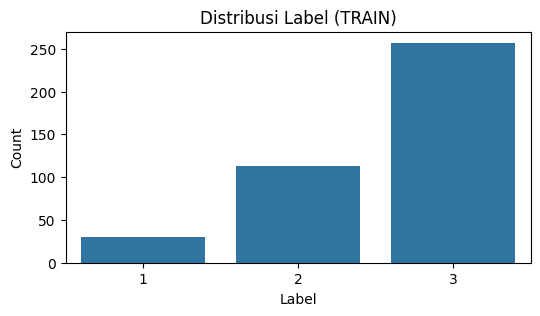

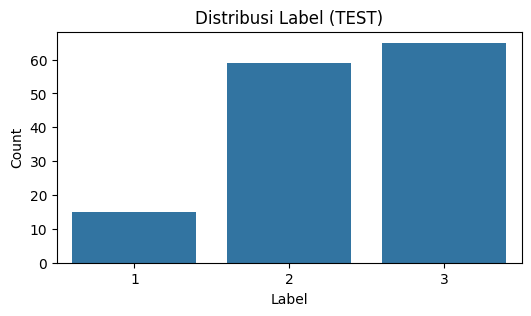

In [9]:
plt.figure(figsize=(6,3))
sns.countplot(x=y_train)
plt.title("Distribusi Label (TRAIN)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(6,3))
sns.countplot(x=y_test)
plt.title("Distribusi Label (TEST)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

Tujuan utama dari langkah visualisasi ini adalah untuk menyajikan representasi grafis yang intuitif mengenai proporsi setiap kelas target yang sebelumnya hanya kita lihat dalam bentuk angka. Penggunaan diagram batang (bar chart) berfungsi untuk memvalidasi secara visual tingkat ketimpangan atau ketidakseimbangan data (class imbalance). Dalam proyek sains data, visualisasi semacam ini sangat krusial untuk memberikan pemahaman cepat mengenai struktur dataset dan menjadi landasan argumen mengapa strategi evaluasi atau teknik pemrosesan khusus (seperti resampling) mungkin diperlukan nantinya.

Berdasarkan hasil visual yang ditampilkan, grafik tersebut mengonfirmasi secara tegas adanya disparitas jumlah sampel yang ekstrem antar kategori. Pada plot data latih (Train), batang yang mewakili Kelas 3 menjulang paling tinggi, mendominasi mayoritas ruang distribusi, disusul oleh Kelas 2. Sementara itu, batang untuk Kelas 1 terlihat sangat pendek dan kerdil dibandingkan dua kelas lainnya. Kondisi visual ini secara gamblang memperlihatkan bahwa model akan "melihat" jauh lebih sedikit contoh dari Kelas 1 selama proses pembelajaran, yang berpotensi menyebabkan model menjadi bias dan cenderung memprediksi kelas mayoritas (Kelas 3) jika tidak ditangani dengan benar.

### *Visualisasi Contoh Time Series*

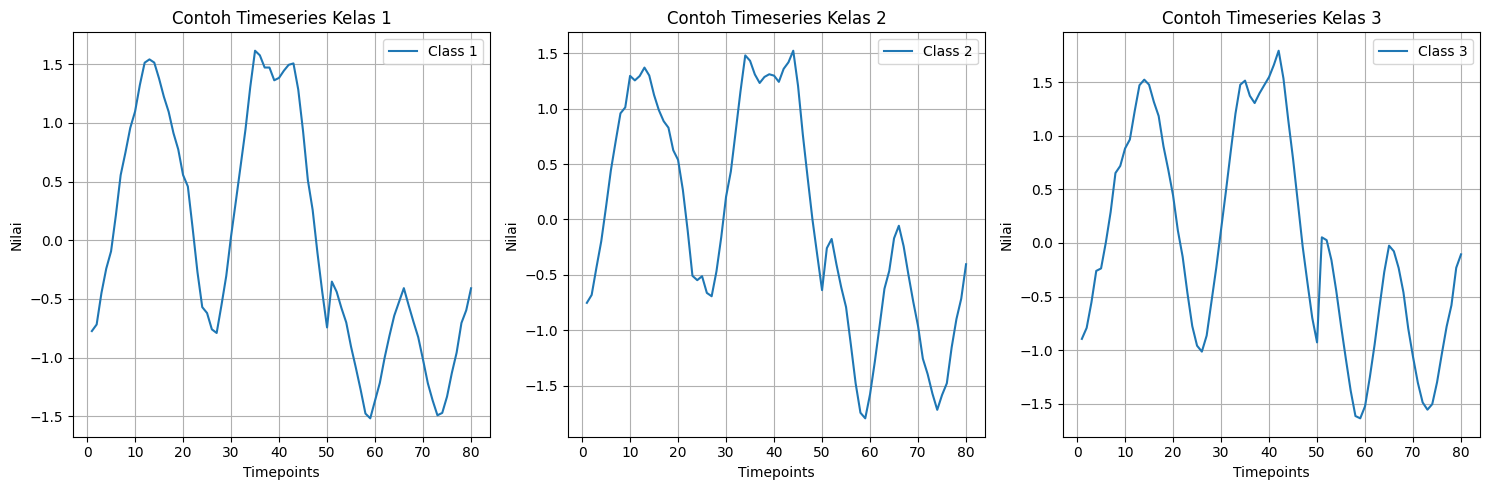

In [10]:
# --- 3. VISUALISASI (PERBAIKAN) ---
unique_classes = np.unique(y_train)

plt.figure(figsize=(15, 5))
for i, c in enumerate(unique_classes):
    # Ambil index pertama yang memiliki kelas c
    idx = np.where(y_train == c)[0][0]
    
    plt.subplot(1, len(unique_classes), i + 1)

    # Jika DataFrame, pakai .iloc[idx]. Jika Numpy, pakai [idx] biasa.
    if isinstance(X_train, pd.DataFrame):
        data_to_plot = X_train.iloc[idx]
    else:
        data_to_plot = X_train[idx]
        
    plt.plot(data_to_plot, label=f'Class {c}')
    plt.title(f'Contoh Timeseries Kelas {c}')
    plt.xlabel('Timepoints')
    plt.ylabel('Nilai')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

Tujuan utama dari blok kode ini adalah untuk melakukan inspeksi visual secara terisolasi terhadap representasi data deret waktu dari setiap kelas target. Berbeda dengan metode visualisasi sebelumnya yang menumpuk semua garis dalam satu bidang gambar, pendekatan ini memecah tampilan menjadi beberapa grafik parsial (subplots) yang berdiri sendiri secara berdampingan. Mekanisme ini bertujuan untuk memberikan pandangan yang lebih fokus dan mendetail terhadap karakteristik morfologi atau pola bentuk gelombang yang spesifik dari masing-masing kategori usia, sehingga kita dapat membandingkan struktur puncak, lembah, dan fluktuasi data antar kelas tanpa gangguan visual akibat tumpang tindih garis (overlapping).

Hasil yang ditampilkan adalah sebuah panel yang memuat tiga grafik garis terpisah, di mana masing-masing grafik merepresentasikan satu sampel representatif dari Kelas 1, Kelas 2, dan Kelas 3. Pada setiap panel visual tersebut, kita dapat mengamati perilaku data di sepanjang titik waktu (sumbu X) dan besaran nilainya (sumbu Y). Melalui perbandingan sisi-ke-sisi ini, perbedaan karakteristik antar kelas menjadi lebih mudah diamati, seperti variasi pada ketinggian amplitudo, ketajaman lengkungan, atau pergeseran fase gelombang yang menjadi fitur pembeda utama bagi algoritma klasifikasi nantinya untuk membedakan kelompok usia berdasarkan outline tulang.

### *Visualisasi Rata-rata Time Series per Kelas*

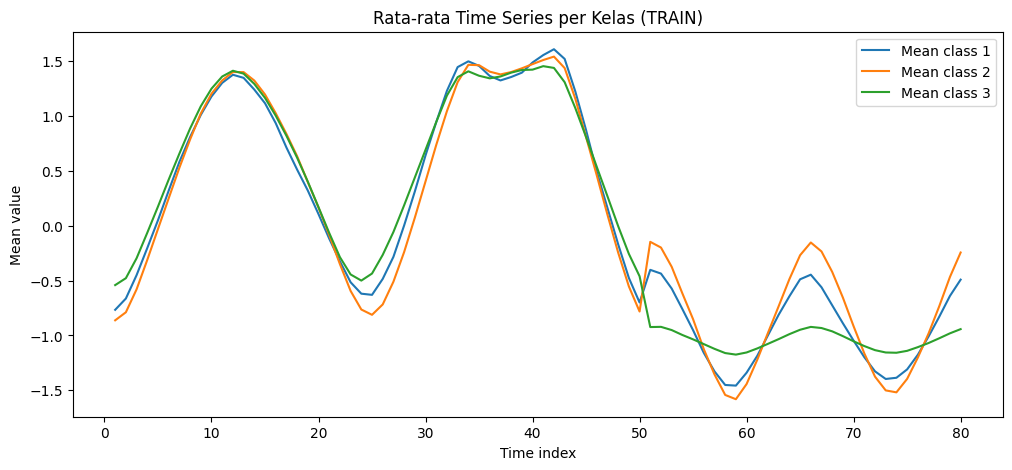

In [11]:
unique_labels = sorted(y_train.unique())

plt.figure(figsize=(12,5))
for label in unique_labels:
    mean_series = X_train[y_train == label].mean(axis=0)
    plt.plot(mean_series, label=f"Mean class {label}")
plt.legend()
plt.title("Rata-rata Time Series per Kelas (TRAIN)")
plt.xlabel("Time index")
plt.ylabel("Mean value")
plt.show()


Tujuan utama dari langkah ini adalah untuk mendapatkan gambaran "pola umum" atau "tanda tangan" (signature) yang paling representatif dari setiap kelas dengan cara menghitung nilai rata-rata (mean) dari seluruh sampel data dalam kelas yang sama. Jika sebelumnya kita melihat sampel individu yang mungkin masih mengandung noise (gangguan) atau variasi unik, teknik perataan ini berfungsi untuk meredam fluktuasi acak tersebut dan menonjolkan tren utama yang konsisten. Hal ini sangat krusial untuk memahami apakah secara statistik terdapat perbedaan bentuk dasar yang signifikan antar kategori usia yang dapat dimanfaatkan oleh model untuk membedakan satu kelas dengan kelas lainnya.

Hasil visualisasi ini menampilkan tiga garis kurva yang merepresentasikan bentuk rata-rata kontur tulang untuk Kelas 1, Kelas 2, dan Kelas 3. Melalui grafik ini, kita dapat melihat dengan lebih jernih di titik waktu (indeks) mana perbedaan antar kelas paling mencolok. Misalnya, kita mungkin melihat bahwa pada indeks waktu tertentu, garis Kelas 3 berada jauh lebih tinggi dibandingkan Kelas 1, atau mungkin ada pergeseran fase gelombang di mana puncak gelombang satu kelas muncul lebih awal dibandingkan yang lain. Jika garis-garis rata-rata ini terlihat saling terpisah dengan jelas (tidak terlalu berimpit), itu adalah indikasi awal yang baik bahwa dataset ini memiliki fitur pembeda yang cukup kuat untuk diklasifikasikan dengan akurasi yang tinggi.

### *Visualisasi PCA*

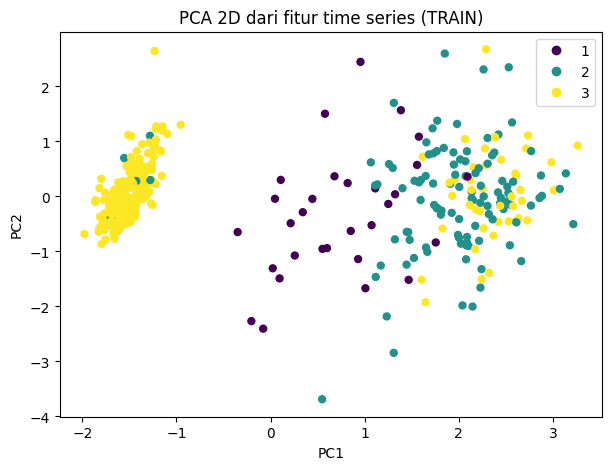

In [12]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train)
plt.figure(figsize=(7,5))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=y_train, cmap="viridis", s=25)
plt.legend(handles=scatter.legend_elements()[0], labels=sorted(unique_labels))
plt.title("PCA 2D dari fitur time series (TRAIN)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

Tujuan utama dari langkah ini adalah untuk melakukan reduksi dimensi guna memvisualisasikan struktur data yang kompleks dalam format yang dapat dicerna oleh mata manusia. Karena data asli memiliki dimensi yang tinggi (80 titik waktu/fitur), kita tidak mungkin memplotnya secara langsung dalam satu grafik koordinat. Oleh karena itu, teknik Principal Component Analysis (PCA) digunakan untuk memadatkan 80 fitur tersebut menjadi dua komponen utama (sumbu X dan Y) yang paling mewakili variasi bentuk data, memungkinkan kita untuk melihat peta penyebaran data dalam ruang dua dimensi.

Hasil visualisasi berupa diagram sebar (scatter plot) ini memperlihatkan bagaimana sampel-sampel dari ketiga kelas (Kelas 1, 2, dan 3) terdistribusi relatif satu sama lain. Melalui pengelompokan titik-titik berwarna ini, kita dapat menilai tingkat kesulitan masalah klasifikasi secara kualitatif. Jika titik-titik dengan warna yang sama berkumpul membentuk klaster yang terpisah tegas dari klaster warna lain, itu menandakan data mudah dipisahkan secara linier. Namun, jika titik-titik antar kelas terlihat banyak yang bercampur atau tumpang tindih (overlapping), hal tersebut mengindikasikan bahwa fitur-fitur antar kelas memiliki kemiripan yang tinggi, sehingga model klasifikasi nantinya akan memerlukan algoritma yang lebih canggih (non-linier) untuk dapat membedakan kategori usia dengan akurat.

## **Data Preprocessing**

### **Mekanisme Pemrosesan Citra dan Ekstraksi Fitur**

Proses transformasi data dari citra mentah menjadi fitur kuantitatif (*timeseries*) dilakukan secara terpusat melalui *Computer-Aided Diagnostic (CAD) Server*. Sistem ini menerapkan alur kerja bertahap yang meliputi pra-pemrosesan citra, identifikasi wilayah anatomis, dan ekstraksi parameter biometrik.

**1. Pra-pemrosesan Citra (*Image Preprocessing*)**
Sebelum analisis tulang dilakukan, citra radiografi yang diunggah ke *CAD Server* melewati serangkaian tahapan standarisasi untuk memastikan kualitas input yang optimal. Layanan pemrosesan ini meliputi:
* **Konversi Format:** Transformasi format citra dari dan ke standar medis DICOM (*Digital Imaging and Communications in Medicine*) untuk menjamin interoperabilitas data.
* **Segmentasi Latar Belakang (*Background Removal*):** Algoritma secara otomatis mendeteksi dan mengeliminasi area latar belakang yang tidak relevan (non-biologis) pada radiograf, sehingga komputasi hanya terfokus pada objek tangan.
* **Normalisasi Tampilan:** Penerapan penyesuaian otomatis pada parameter *window-level* dan koreksi *gamma*, serta fungsi penskalaan (*scaling*) untuk menstandarisasi karakteristik visual citra sebelum dianalisis lebih lanjut.

**2. Definisi *Region of Interest* (ROI)**
Metodologi ekstraksi fitur pada sistem ini tidak menganalisis keseluruhan tangan secara global, melainkan memecahnya menjadi wilayah-wilayah anatomis spesifik yang dikenal sebagai *Region of Interest* (ROI). Berdasarkan studi terdahulu oleh Pietka dan Huang, sistem mengidentifikasi tiga ROI utama:
* **PROI (*Phalangeal Region of Interest*):** Wilayah yang mencakup tulang-tulang jari (phalanx). Dataset *DistalPhalanxOutline* yang digunakan dalam penelitian ini merupakan hasil ekstraksi spesifik dari wilayah ini, khususnya pada kontur tulang distal.
* **EROI (*Epiphyseal Region of Interest*):** Wilayah lempeng pertumbuhan (epifisis) yang krusial untuk menentukan tingkat kematangan tulang pada masa pubertas.
* **CROI (*Carpal Bone Region of Interest*):** Wilayah tulang-tulang pergelangan tangan (karpal).

![image-tulang](image\foto-tulang-UAS.png)

**3. Ekstraksi Fitur Kuantitatif**
Setelah ROI teridentifikasi, sistem menerapkan teknik pemrosesan citra (berbasis *image processing*) untuk mengekstrak fitur kuantitatif yang merepresentasikan geometri dan morfologi tulang. Fitur-fitur ini mencakup pengukuran panjang, lebar, area, dan bentuk kontur tulang yang berkorelasi langsung dengan indeks kematangan Tanner, usia, jenis kelamin, dan ras. Hasil ekstraksi ini kemudian diklasifikasikan menjadi parameter usia tulang parsial, yaitu *Phalangeal Bone Age* (PBA), *Carpal Bone Age* (CBA), dan *Epiphyseal Bone Age* (EBA).

**4. Lingkungan Komputasi**
Seluruh algoritma pemrosesan citra dan ekstraksi fitur ini dikembangkan di atas platform *Sun Solaris*. Implementasinya memanfaatkan integrasi berbagai pustaka komputasi tingkat tinggi, termasuk *Matlab* (MathWorks, Inc.), *X Image Library* (XIL), serta algoritma *in-house* yang dikembangkan khusus untuk analisis morfometri tulang.


In [13]:
X_train = df_train.iloc[:, 1:].values
y_train_raw = df_train.iloc[:, 0].values

X_test = df_test.iloc[:, 1:].values
y_test_raw = df_test.iloc[:, 0].values

# 2. Label Encoding (Mengubah 1,2,3 menjadi 0,1,2)
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw)
y_test = le.transform(y_test_raw)

print("Status Preprocessing:")
print(f"1. Normalisasi: SUDAH BAWAAN (Mean={X_train[0].mean():.2f}, Std={X_train[0].std():.2f})")
print(f"2. Label Encoding: SUDAH DILAKUKAN. Label asli {np.unique(y_train_raw)} diubah menjadi {np.unique(y_train)}.")
print(f"3. Bentuk Data (Shape): {X_train.shape}")

Status Preprocessing:
1. Normalisasi: SUDAH BAWAAN (Mean=0.00, Std=0.99)
2. Label Encoding: SUDAH DILAKUKAN. Label asli [1 2 3] diubah menjadi [0 1 2].
3. Bentuk Data (Shape): (400, 80)


Tujuan utama dari blok kode ini adalah untuk melakukan standardisasi format data agar kompatibel dengan persyaratan teknis algoritma pembelajaran mesin. Secara spesifik, kode ini melakukan dua hal krusial: pertama, mengonversi label kategori asli (yang bernilai 1, 2, dan 3) menjadi urutan numerik yang dimulai dari nol (0, 1, 2) menggunakan teknik Label Encoding. Hal ini penting karena banyak kerangka kerja Deep Learning dan beberapa algoritma klasifikasi mensyaratkan target kelas dalam format indeks berbasis nol. Kedua, kode ini melakukan verifikasi statistik untuk memastikan apakah data fitur sudah memiliki skala yang seragam (normalized), sebuah kondisi yang sangat membantu dalam mempercepat konvergensi model selama proses pelatihan.

Berdasarkan hasil keluaran (output) yang ditampilkan, kita mendapatkan konfirmasi bahwa data sudah dalam kondisi yang sangat prima untuk diolah. Nilai rata-rata (mean) yang mendekati 0.00 dan standar deviasi (std) yang mendekati 0.99 pada sampel data menunjukkan bahwa dataset ini sudah melalui proses normalisasi standar (Z-score normalization) dari sumbernya, sehingga kita tidak perlu lagi melakukan penskalaan fitur secara manual. Selain itu, transformasi label telah berhasil dilakukan dengan sempurna, di mana kelas 1, 2, dan 3 kini telah terpetakan menjadi 0, 1, dan 2. Dimensi data juga tetap konsisten dengan 400 sampel dan 80 fitur, menegaskan bahwa integritas struktur data tetap terjaga selama proses transformasi ini.

In [14]:
def smote_dtw(X, y, target_class, k_neighbors=3, N=100):
    """
    SMOTE-DTW untuk time series 1D.
    X = array (n_samples, n_timestamps)
    y = label array
    target_class = kelas yang ingin diperbanyak
    N = berapa banyak sampel baru yang ingin dibuat
    """
    # pilih data minoritas
    X_minority = X[y == target_class]
    n_min = len(X_minority)
    
    synthetic_samples = []

    for _ in range(N):
        # pilih 1 sampel acak dari kelas minoritas
        idx = np.random.randint(0, n_min)
        x_i = X_minority[idx]

        # cari k tetangga terdekat menggunakan DTW
        distances = []
        for j in range(n_min):
            if j != idx:
                d = dtw.distance(x_i, X_minority[j])
                distances.append((d, j))

        distances.sort(key=lambda x: x[0])
        neighbors = [j for _, j in distances[:k_neighbors]]

        # pilih salah satu tetangga
        nn = X_minority[np.random.choice(neighbors)]

        # interpolasi linear → menghasilkan time series baru
        alpha = np.random.rand()
        synthetic = alpha * x_i + (1 - alpha) * nn
        synthetic_samples.append(synthetic)

    return np.array(synthetic_samples)


In [15]:
# ---------------------------------------
# 1) Menentukan jumlah sampel tambahan
# ---------------------------------------
unique, counts = np.unique(y_train, return_counts=True)
print(dict(zip(unique, counts)))

# kelas minor biasanya 0 dan 1
# misal tambahkan 100 sampel kelas 0 dan 80 sampel kelas 1
syn_0 = smote_dtw(X_train, y_train, target_class=0, N=227)
syn_1 = smote_dtw(X_train, y_train, target_class=1, N=144)

# label tambahan
y_syn_0 = np.array([0] * len(syn_0))
y_syn_1 = np.array([1] * len(syn_1))

# gabungkan
X_train_smote = np.vstack([X_train, syn_0, syn_1])
y_train_smote = np.concatenate([y_train, y_syn_0, y_syn_1])

print("Bentuk baru setelah SMOTE-DTW:", X_train_smote.shape)

{np.int64(0): np.int64(30), np.int64(1): np.int64(113), np.int64(2): np.int64(257)}
Bentuk baru setelah SMOTE-DTW: (771, 80)


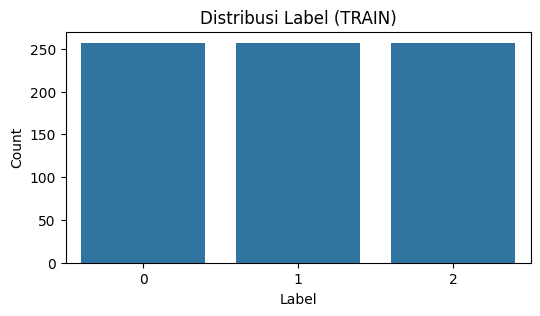

In [16]:
plt.figure(figsize=(6,3))
sns.countplot(x=y_train_smote)
plt.title("Distribusi Label (TRAIN)")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## **Modeling & Evaluasi**

In [17]:
# 1-NN Euclidean
model_euclid = KNeighborsClassifier(n_neighbors=1, metric='euclidean')
model_euclid.fit(X_train, y_train)

pred_euclid = model_euclid.predict(X_test)

print("Accuracy (1-NN Euclidean):", accuracy_score(y_test, pred_euclid))
print("\nClassification Report:\n", classification_report(y_test, pred_euclid))


Accuracy (1-NN Euclidean): 0.6258992805755396

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.73      0.59        15
           1       0.58      0.49      0.53        59
           2       0.70      0.72      0.71        65

    accuracy                           0.63       139
   macro avg       0.59      0.65      0.61       139
weighted avg       0.63      0.63      0.62       139



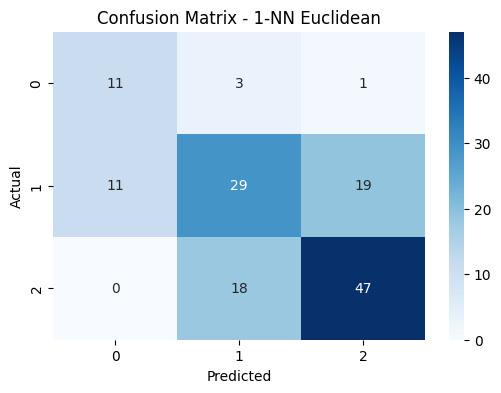

In [18]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, pred_euclid), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - 1-NN Euclidean")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
# ==========================
# 1-NN Euclidean + SMOTE
# ==========================

# Gunakan data hasil SMOTE untuk modeling
model_euclid_sm = KNeighborsClassifier(n_neighbors=1, metric='euclidean')

model_euclid_sm.fit(X_train_smote, y_train_smote)

pred_euclid_sm = model_euclid_sm.predict(X_test)

# Evaluasi
print("=== 1-NN Euclidean + SMOTE ===")
print("Accuracy:", accuracy_score(y_test, pred_euclid_sm))
print("\nClassification Report:\n", classification_report(y_test, pred_euclid_sm))


=== 1-NN Euclidean + SMOTE ===
Accuracy: 0.6474820143884892

Classification Report:
               precision    recall  f1-score   support

           0       0.52      0.80      0.63        15
           1       0.59      0.59      0.59        59
           2       0.75      0.66      0.70        65

    accuracy                           0.65       139
   macro avg       0.62      0.68      0.64       139
weighted avg       0.66      0.65      0.65       139



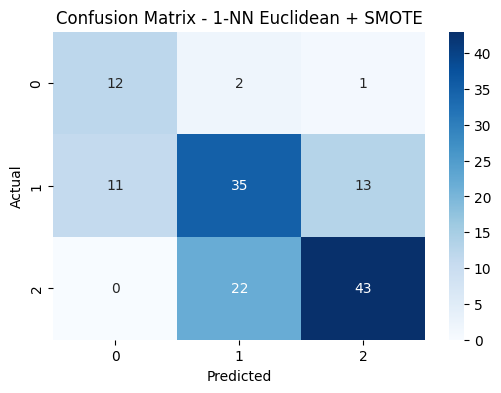

In [20]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, pred_euclid_sm), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - 1-NN Euclidean + SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [21]:
# Perlu reshape karena tslearn memakai format (n_samples, n_timestamps, 1)
X_train_ts = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_ts = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# 1-NN DTW
model_dtw = KNeighborsTimeSeriesClassifier(n_neighbors=1, metric="dtw")
model_dtw.fit(X_train_ts, y_train)

pred_dtw = model_dtw.predict(X_test_ts)

print("Accuracy (1-NN DTW):", accuracy_score(y_test, pred_dtw))
print("\nClassification Report:\n", classification_report(y_test, pred_dtw))


Accuracy (1-NN DTW): 0.7697841726618705

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.80      0.75        15
           1       0.76      0.69      0.73        59
           2       0.79      0.83      0.81        65

    accuracy                           0.77       139
   macro avg       0.75      0.78      0.76       139
weighted avg       0.77      0.77      0.77       139



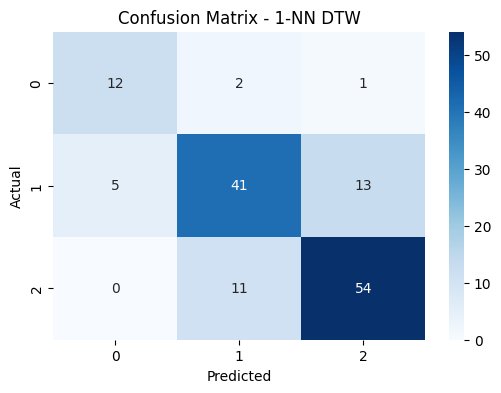

In [22]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, pred_dtw), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - 1-NN DTW")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [23]:
X_train_ts = X_train_smote.reshape((X_train_smote.shape[0], X_train_smote.shape[1], 1))
X_test_ts = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# ==========================
# 1-NN DTW + SMOTE
# ==========================
model_dtw = KNeighborsTimeSeriesClassifier(n_neighbors=1, metric="dtw")
model_dtw.fit(X_train_ts, y_train_smote)

# Prediksi tetap menggunakan test asli
pred_dtw_smoote = model_dtw.predict(X_test_ts)

# Evaluasi
print("=== 1-NN DTW + SMOTE ===")
print("Accuracy:", accuracy_score(y_test, pred_dtw_smoote))
print("\nClassification Report:\n", classification_report(y_test, pred_dtw_smoote))


=== 1-NN DTW + SMOTE ===
Accuracy: 0.7338129496402878

Classification Report:
               precision    recall  f1-score   support

           0       0.57      0.87      0.68        15
           1       0.70      0.73      0.72        59
           2       0.84      0.71      0.77        65

    accuracy                           0.73       139
   macro avg       0.70      0.77      0.72       139
weighted avg       0.75      0.73      0.74       139



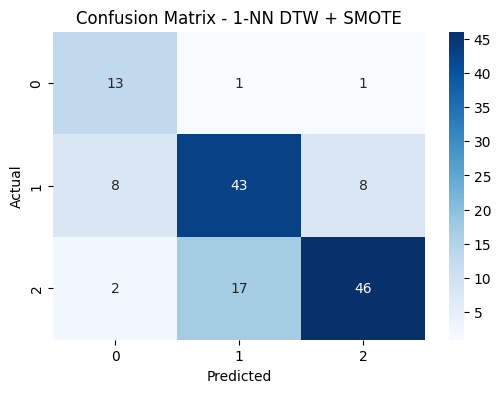

In [24]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, pred_dtw_smoote), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - 1-NN DTW + SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [25]:
# TRAINING RANDOM FOREST
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# =========================
# EVALUASI RANDOM FOREST
# =========================
print("=== Random Forest Accuracy ===")
print(accuracy_score(y_test, rf_pred))

print("\n=== Classification Report ===")
print(classification_report(y_test, rf_pred))


=== Random Forest Accuracy ===
0.762589928057554

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.75      0.60      0.67        15
           1       0.68      0.85      0.75        59
           2       0.89      0.72      0.80        65

    accuracy                           0.76       139
   macro avg       0.77      0.72      0.74       139
weighted avg       0.78      0.76      0.76       139



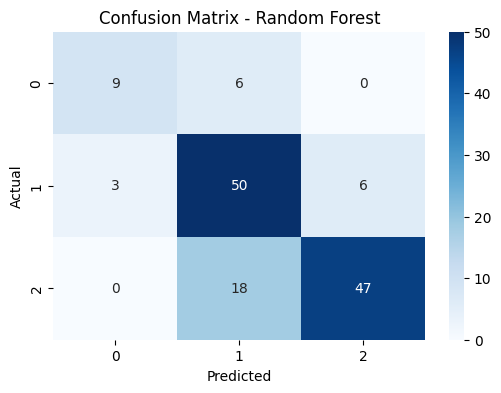

In [26]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [27]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42
)

rf_balanced.fit(X_train_smote, y_train_smote)
pred_bal = rf_balanced.predict(X_test)

print("=== Random Forest Accuracy + SMOTE + Class Weight Balance ===")
print(accuracy_score(y_test, pred_bal))


print("\n=== Classification Report ===")
print(classification_report(y_test, pred_bal))


=== Random Forest Accuracy + SMOTE + Class Weight Balance ===
0.7553956834532374

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.73      0.73      0.73        15
           1       0.66      0.86      0.75        59
           2       0.91      0.66      0.77        65

    accuracy                           0.76       139
   macro avg       0.77      0.75      0.75       139
weighted avg       0.79      0.76      0.76       139



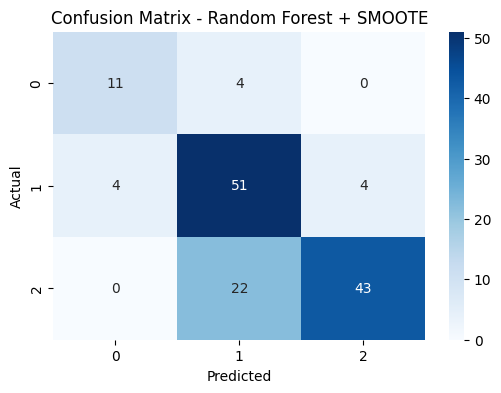

In [ ]:
# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, pred_bal), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest + SMOOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## **Deployment Model**

In [30]:
import joblib

# 1. Pilih model terbaik Anda (Ganti variabel ini sesuai hasil akurasi tertinggi)
# Contoh: Jika yang terbaik adalah KNN DTW + SMOTE
model_final = model_dtw 

# 2. Simpan Model dan Label Encoder
joblib.dump(model_final, 'saved_models/uas/best_model_bone_age.pkl')
joblib.dump(le, 'saved_models/uas/label_encoder.pkl')

print("Model dan Encoder berhasil disimpan!")

Model dan Encoder berhasil disimpan!
